# Regresión Logística — Online Shoppers Purchasing Intention

Clasificación binaria de la variable `Revenue` (compra / no compra) sobre el
conjunto *Online Shoppers Purchasing Intention* (UCI, id 468, licencia CC BY 4.0).

El dataset se carga desde `../data/online_shoppers_intention.csv`.

## 1. Importar librerías

Cargamos las librerías necesarias: `numpy` y `pandas` para datos,
`matplotlib` para visualización, `os` para el sistema de archivos y las
utilidades de `scikit-learn` para preprocesar, entrenar y evaluar la regresión
logística. También creamos la carpeta donde se guardarán las figuras.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_recall_fscore_support,
)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

os.makedirs("../reports/figures", exist_ok=True)
print("Librerías importadas y carpeta de figuras creada.")

Librerías importadas y carpeta de figuras creada.


## 2. Cargar datos

Leemos el CSV con `pd.read_csv` usando una ruta relativa (compatible con
Google Colab). Mostramos las primeras filas, las dimensiones y las variables
de entrada y la variable objetivo.

In [2]:
datos = pd.read_csv("../data/online_shoppers_intention.csv")

print("Primeras filas del dataset:")
display(datos.head())

print("\nNúmero de filas y columnas:", datos.shape)

variables_entrada = [col for col in datos.columns if col != "Revenue"]
variable_objetivo = "Revenue"

print("\nVariables de entrada (", len(variables_entrada), "):", variables_entrada)
print("Variable objetivo:", variable_objetivo)

Primeras filas del dataset:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False



Número de filas y columnas: (12330, 18)

Variables de entrada ( 17 ): ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']
Variable objetivo: Revenue


## 3. Exploración de datos

Revisamos tipos y valores no nulos (`info()`), estadísticos descriptivos
(`describe()`), la distribución de la variable objetivo (`value_counts`) y la
presencia de valores faltantes. También visualizamos la distribución de clases.

=== info() ===
<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType       

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000



=== value_counts de Revenue (absoluto) ===
Revenue
False    10422
True      1908
Name: count, dtype: int64

=== value_counts de Revenue (proporción) ===
Revenue
False    0.845255
True     0.154745
Name: proportion, dtype: float64

=== Valores nulos por columna ===
Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64


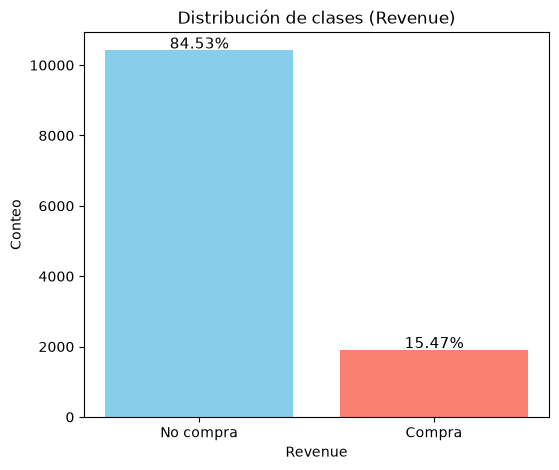

In [3]:
print("=== info() ===")
datos.info()

print("\n=== describe() ===")
display(datos.describe())

print("\n=== value_counts de Revenue (absoluto) ===")
print(datos["Revenue"].value_counts())

print("\n=== value_counts de Revenue (proporción) ===")
print(datos["Revenue"].value_counts(normalize=True))

print("\n=== Valores nulos por columna ===")
print(datos.isnull().sum())

# Gráfico de distribución de clases
conteo = datos["Revenue"].map({False: "No compra", True: "Compra"}).value_counts()
proporcion = datos["Revenue"].map({False: "No compra", True: "Compra"}).value_counts(normalize=True)

plt.figure(figsize=(6, 5))
barras = plt.bar(conteo.index, conteo.values, color=["skyblue", "salmon"])
for barra, prop in zip(barras, proporcion.values):
    plt.text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 50,
             f"{prop:.2%}", ha="center", fontsize=11)
plt.xlabel("Revenue")
plt.ylabel("Conteo")
plt.title("Distribución de clases (Revenue)")
plt.savefig("../reports/figures/03_distribucion_clases.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Visualización inicial

Exploramos visualmente la relación entre la duración en páginas de producto y
la compra (scatter), y comparamos la tasa de compra según el tipo de visitante.

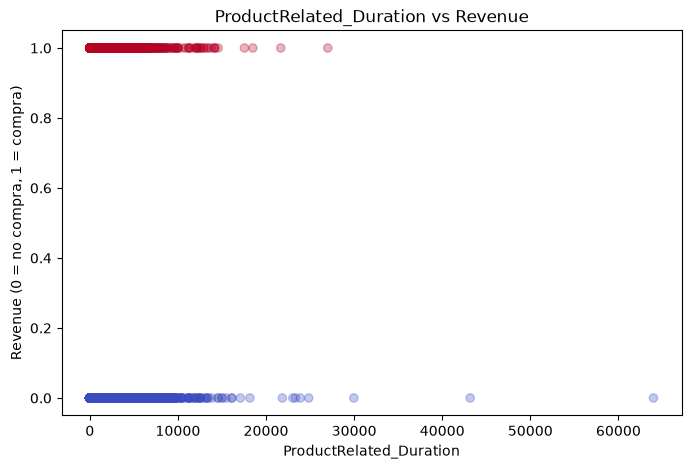

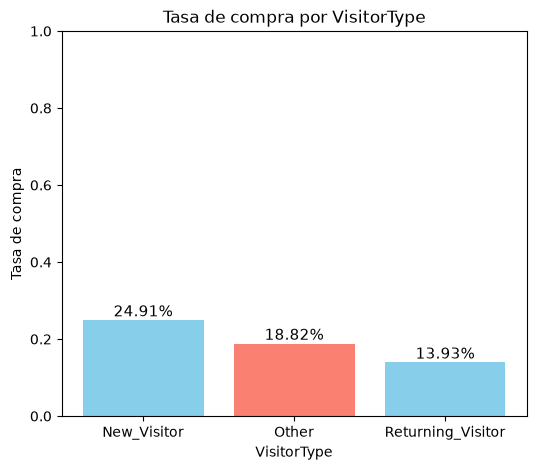

In [4]:
compra = datos["Revenue"].astype(int)

plt.figure(figsize=(8, 5))
plt.scatter(datos["ProductRelated_Duration"], compra, alpha=0.3, c=compra, cmap="coolwarm")
plt.xlabel("ProductRelated_Duration")
plt.ylabel("Revenue (0 = no compra, 1 = compra)")
plt.title("ProductRelated_Duration vs Revenue")
plt.savefig("../reports/figures/04_scatter_duracion_vs_compra.png", dpi=150, bbox_inches="tight")
plt.show()

tasa_visitante = compra.groupby(datos["VisitorType"]).mean()

plt.figure(figsize=(6, 5))
barras = plt.bar(tasa_visitante.index, tasa_visitante.values, color=["skyblue", "salmon"])
for barra, valor in zip(barras, tasa_visitante.values):
    plt.text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 0.01,
             f"{valor:.2%}", ha="center", fontsize=11)
plt.xlabel("VisitorType")
plt.ylabel("Tasa de compra")
plt.ylim(0, 1)
plt.title("Tasa de compra por VisitorType")
plt.savefig("../reports/figures/04_tasa_compra_visitor_type.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Definir X e y

Separamos las variables de entrada `X` de la variable objetivo `y`, convirtiendo
`Revenue` a valores numéricos 0 (no compra) y 1 (compra).

In [5]:
X = datos.drop(columns=["Revenue"])
y = datos["Revenue"].astype(int)

print("Forma de X:", X.shape)
print("Forma de y:", y.shape)
print("\nDistribución de y:")
print(y.value_counts())

Forma de X: (12330, 17)
Forma de y: (12330,)

Distribución de y:
Revenue
0    10422
1     1908
Name: count, dtype: int64


## 6. División train/test

Dividimos en entrenamiento y prueba con `stratify=y` para conservar la
proporción de clases en ambos conjuntos, y `random_state=42` para
reproducibilidad.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print("Tamaño del conjunto de entrenamiento:", X_train.shape[0])
print("Tamaño del conjunto de prueba:", X_test.shape[0])

print("\nDistribución de clases en train:")
print(y_train.value_counts())
print("Proporción en train:")
print(y_train.value_counts(normalize=True))

print("\nDistribución de clases en test:")
print(y_test.value_counts())
print("Proporción en test:")
print(y_test.value_counts(normalize=True))

Tamaño del conjunto de entrenamiento: 9247
Tamaño del conjunto de prueba: 3083

Distribución de clases en train:
Revenue
0    7816
1    1431
Name: count, dtype: int64
Proporción en train:
Revenue
0    0.845247
1    0.154753
Name: proportion, dtype: float64

Distribución de clases en test:
Revenue
0    2606
1     477
Name: count, dtype: int64
Proporción en test:
Revenue
0    0.845281
1    0.154719
Name: proportion, dtype: float64


## 7. Crear y entrenar el modelo

Construimos un `Pipeline` con un `ColumnTransformer`: `StandardScaler` para las
variables numéricas y `OneHotEncoder` para las categóricas (`Month`,
`VisitorType`, `Weekend`). Luego ajustamos una regresión logística. El
preprocesamiento se ajusta **solo** con el conjunto de entrenamiento.

In [7]:
columnas_categoricas = ["Month", "VisitorType", "Weekend"]
columnas_numericas = [col for col in X.columns if col not in columnas_categoricas]

print("Columnas numéricas (", len(columnas_numericas), "):", columnas_numericas)
print("Columnas categóricas (", len(columnas_categoricas), "):", columnas_categoricas)

preprocesador = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), columnas_numericas),
        ("cat", OneHotEncoder(handle_unknown="ignore"), columnas_categoricas),
    ]
)

modelo = Pipeline(
    steps=[
        ("preprocesador", preprocesador),
        ("clasificador", LogisticRegression(max_iter=1000)),
    ]
)

modelo.fit(X_train, y_train)
print("\nModelo entrenado con éxito.")

Columnas numéricas ( 14 ): ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']
Columnas categóricas ( 3 ): ['Month', 'VisitorType', 'Weekend']

Modelo entrenado con éxito.


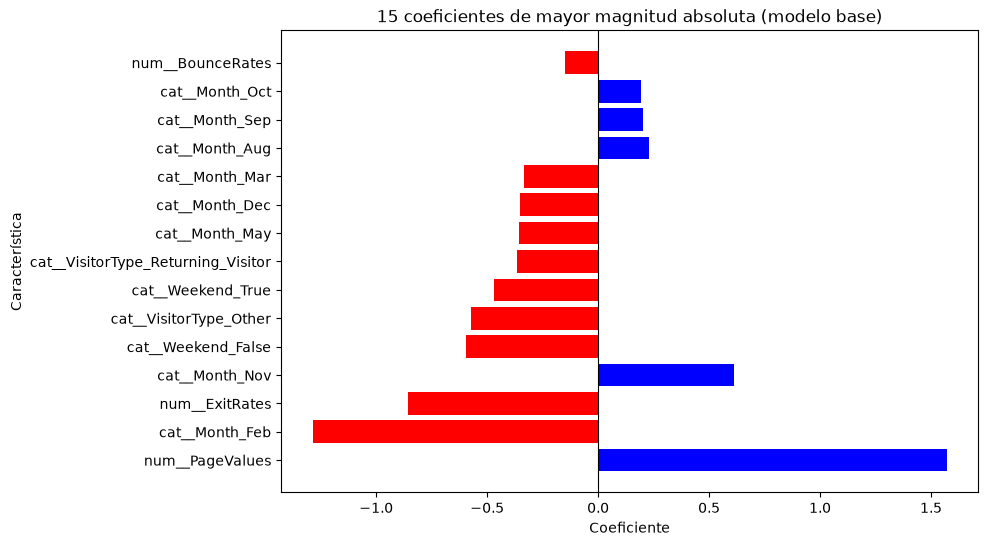

In [8]:
nombres = modelo.named_steps["preprocesador"].get_feature_names_out()
coeficientes = modelo.named_steps["clasificador"].coef_[0]

importancia = pd.Series(coeficientes, index=nombres)
top = importancia.reindex(importancia.abs().sort_values(ascending=False).index).head(15)

colores = ["red" if valor < 0 else "blue" for valor in top.values]

plt.figure(figsize=(9, 6))
plt.barh(top.index, top.values, color=colores)
plt.xlabel("Coeficiente")
plt.ylabel("Característica")
plt.title("15 coeficientes de mayor magnitud absoluta (modelo base)")
plt.axvline(0, color="black", linewidth=0.8)
plt.savefig("../reports/figures/07_coeficientes_modelo.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Predicciones

Obtenemos la clase predicha con `predict` (aplica el umbral por defecto de 0.50)
y las probabilidades de pertenecer a cada clase con `predict_proba`.

In [9]:
y_pred = modelo.predict(X_test)
probabilidades = modelo.predict_proba(X_test)

print("Clases predichas (primeras 20):")
print(y_pred[:20])

print("\nProbabilidades (primeras 20 filas; columnas: [P(no compra), P(compra)]):")
print(probabilidades[:20])

Clases predichas (primeras 20):
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

Probabilidades (primeras 20 filas; columnas: [P(no compra), P(compra)]):
[[0.90761109 0.09238891]
 [0.91683979 0.08316021]
 [0.95621807 0.04378193]
 [0.89191797 0.10808203]
 [0.93379885 0.06620115]
 [0.84171667 0.15828333]
 [0.98064358 0.01935642]
 [0.88269745 0.11730255]
 [0.70102442 0.29897558]
 [0.76707404 0.23292596]
 [0.83696184 0.16303816]
 [0.9396426  0.0603574 ]
 [0.92089567 0.07910433]
 [0.96249951 0.03750049]
 [0.89734186 0.10265814]
 [0.90558229 0.09441771]
 [0.97062959 0.02937041]
 [0.81071223 0.18928777]
 [0.9100072  0.0899928 ]
 [0.74573398 0.25426602]]


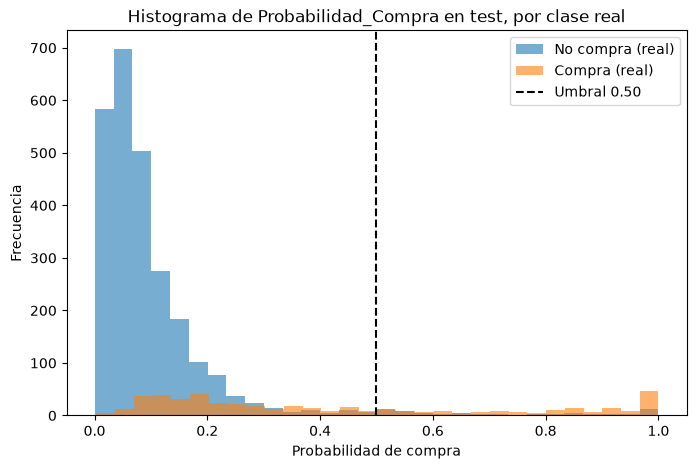

In [10]:
prob_compra_test = probabilidades[:, 1]

plt.figure(figsize=(8, 5))
plt.hist(prob_compra_test[y_test == 0], bins=30, alpha=0.6, label="No compra (real)")
plt.hist(prob_compra_test[y_test == 1], bins=30, alpha=0.6, label="Compra (real)")
plt.axvline(0.50, color="black", linestyle="--", label="Umbral 0.50")
plt.xlabel("Probabilidad de compra")
plt.ylabel("Frecuencia")
plt.title("Histograma de Probabilidad_Compra en test, por clase real")
plt.legend()
plt.savefig("../reports/figures/08_histograma_probabilidades.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. DataFrame comparativo

Comparamos el valor real con la predicción y con las probabilidades de cada
clase para las primeras 20 filas del conjunto de prueba.

In [11]:
comparacion = pd.DataFrame({
    "Real": y_test.values,
    "Predicho": y_pred,
    "Probabilidad_No_Compra": probabilidades[:, 0],
    "Probabilidad_Compra": probabilidades[:, 1],
})

print("Comparación (primeras 20 filas):")
display(comparacion.head(20))

Comparación (primeras 20 filas):


,Real,Predicho,Probabilidad_No_Compra,Probabilidad_Compra
0,0,0,0.907611,0.092389
1,0,0,0.916840,0.083160
2,0,0,0.956218,0.043782
3,0,0,0.891918,0.108082
4,0,0,0.933799,0.066201
5,0,0,0.841717,0.158283
6,0,0,0.980644,0.019356
7,0,0,0.882697,0.117303
8,0,0,0.701024,0.298976
9,0,0,0.767074,0.232926


## 10. Evaluación del modelo

Calculamos exactitud (accuracy), matriz de confusión y reporte de clasificación,
y comparamos contra un clasificador trivial que siempre predice "no compra".

In [12]:
accuracy = accuracy_score(y_test, y_pred)
matriz = confusion_matrix(y_test, y_pred)
TN, FP, FN, TP = matriz.ravel()

print("Accuracy del modelo (umbral 0.50):", accuracy)
print("\nMatriz de confusión (filas = real, columnas = predicho):")
print(matriz)
print("\nTN (verdaderos negativos):", TN)
print("FP (falsos positivos):", FP)
print("FN (falsos negativos):", FN)
print("TP (verdaderos positivos):", TP)

print("\n=== classification_report ===")
print(classification_report(y_test, y_pred))

Accuracy del modelo (umbral 0.50): 0.8780408692831657

Matriz de confusión (filas = real, columnas = predicho):
[[2539   67]
 [ 309  168]]

TN (verdaderos negativos): 2539
FP (falsos positivos): 67
FN (falsos negativos): 309
TP (verdaderos positivos): 168

=== classification_report ===
              precision    recall  f1-score   support

           0       0.89      0.97      0.93      2606
           1       0.71      0.35      0.47       477

    accuracy                           0.88      3083
   macro avg       0.80      0.66      0.70      3083
weighted avg       0.86      0.88      0.86      3083



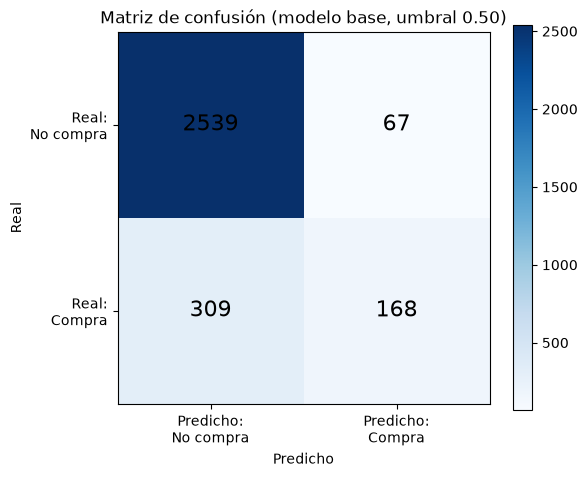

In [13]:
plt.figure(figsize=(6, 5))
plt.imshow(matriz, cmap="Blues")
plt.colorbar()
for i in range(2):
    for j in range(2):
        plt.text(j, i, matriz[i, j], ha="center", va="center", fontsize=16)
plt.xticks([0, 1], ["Predicho:\nNo compra", "Predicho:\nCompra"])
plt.yticks([0, 1], ["Real:\nNo compra", "Real:\nCompra"])
plt.xlabel("Predicho")
plt.ylabel("Real")
plt.title("Matriz de confusión (modelo base, umbral 0.50)")
plt.savefig("../reports/figures/10_matriz_confusion_base.png", dpi=150, bbox_inches="tight")
plt.show()

Accuracy del clasificador trivial (siempre 'no compra'): 0.8452805708725267
Matriz de confusión del trivial:
[[2606    0]
 [ 477    0]]


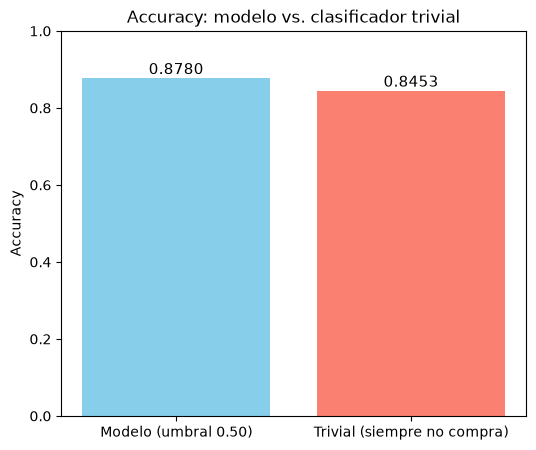

In [14]:
y_trivial = np.zeros_like(y_test)
accuracy_trivial = accuracy_score(y_test, y_trivial)
matriz_trivial = confusion_matrix(y_test, y_trivial)
TN_t, FP_t, FN_t, TP_t = matriz_trivial.ravel()

print("Accuracy del clasificador trivial (siempre 'no compra'):", accuracy_trivial)
print("Matriz de confusión del trivial:")
print(matriz_trivial)

plt.figure(figsize=(6, 5))
barras = plt.bar(["Modelo (umbral 0.50)", "Trivial (siempre no compra)"],
                 [accuracy, accuracy_trivial], color=["skyblue", "salmon"])
for barra, valor in zip(barras, [accuracy, accuracy_trivial]):
    plt.text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 0.01,
             f"{valor:.4f}", ha="center", fontsize=11)
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.title("Accuracy: modelo vs. clasificador trivial")
plt.savefig("../reports/figures/10_accuracy_vs_trivial.png", dpi=150, bbox_inches="tight")
plt.show()

In [15]:
p_base, r_base, f_base, _ = precision_recall_fscore_support(y_test, y_pred, pos_label=1)

print("=== Resumen para el informe (sección 10) ===")
print(f"Accuracy del modelo: {accuracy:.4f}")
print(f"Matriz de confusión -> TN: {TN}, FP: {FP}, FN: {FN}, TP: {TP}")
print(f"Clase 1 (compra) -> Precision: {p_base[1]:.4f}, Recall: {r_base[1]:.4f}, F1: {f_base[1]:.4f}")
print(f"Accuracy del clasificador trivial: {accuracy_trivial:.4f}")
print(f"Diferencia respecto al trivial: {accuracy - accuracy_trivial:.4f}")

=== Resumen para el informe (sección 10) ===
Accuracy del modelo: 0.8780
Matriz de confusión -> TN: 2539, FP: 67, FN: 309, TP: 168
Clase 1 (compra) -> Precision: 0.7149, Recall: 0.3522, F1: 0.4719
Accuracy del clasificador trivial: 0.8453
Diferencia respecto al trivial: 0.0328


## 11. Umbral de decisión

La regresión logística produce una probabilidad; la clase final depende del
umbral elegido. Probamos 0.50, 0.60 y 0.30 y medimos cómo cambian las métricas
y las predicciones respecto al umbral por defecto.

In [16]:
prob_compra_test = probabilidades[:, 1]

y_pred_030 = (prob_compra_test >= 0.30).astype(int)
y_pred_050 = (prob_compra_test >= 0.50).astype(int)
y_pred_060 = (prob_compra_test >= 0.60).astype(int)

predicciones = {0.30: y_pred_030, 0.50: y_pred_050, 0.60: y_pred_060}

tabla = []
for umbral in [0.30, 0.50, 0.60]:
    y_pred_u = predicciones[umbral]
    p, r, f, _ = precision_recall_fscore_support(y_test, y_pred_u, pos_label=1)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_u).ravel()
    tabla.append({
        "Umbral": umbral,
        "Precision (clase 1)": p[1],
        "Recall (clase 1)": r[1],
        "F1 (clase 1)": f[1],
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    })

tabla_umbrales = pd.DataFrame(tabla)
print("Tabla resumen por umbral:")
display(tabla_umbrales)

Tabla resumen por umbral:


,Umbral,Precision (clase 1),Recall (clase 1),F1 (clase 1),TN,FP,FN,TP
0,0.3,0.673854,0.524109,0.589623,2485,121,227,250
1,0.5,0.714894,0.352201,0.471910,2539,67,309,168
2,0.6,0.771739,0.297694,0.429652,2564,42,335,142


In [17]:
print("Predicciones que cambian respecto al umbral 0.50:")
print(f"  Umbral 0.30: {(y_pred_030 != y_pred_050).sum()} predicciones cambian")
print(f"  Umbral 0.60: {(y_pred_060 != y_pred_050).sum()} predicciones cambian")

Predicciones que cambian respecto al umbral 0.50:
  Umbral 0.30: 136 predicciones cambian
  Umbral 0.60: 51 predicciones cambian


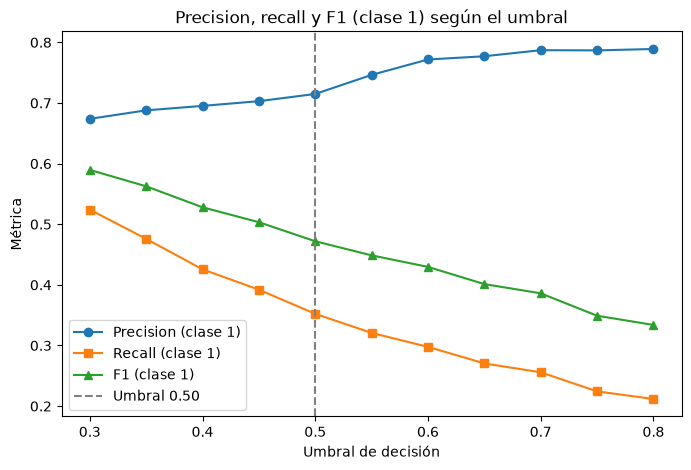

In [18]:
umbrales_barrido = np.arange(0.30, 0.81, 0.05)
precisiones, recalls, f1s = [], [], []

for umbral in umbrales_barrido:
    y_pred_u = (prob_compra_test >= umbral).astype(int)
    p, r, f, _ = precision_recall_fscore_support(y_test, y_pred_u, pos_label=1)
    precisiones.append(p[1])
    recalls.append(r[1])
    f1s.append(f[1])

plt.figure(figsize=(8, 5))
plt.plot(umbrales_barrido, precisiones, marker="o", label="Precision (clase 1)")
plt.plot(umbrales_barrido, recalls, marker="s", label="Recall (clase 1)")
plt.plot(umbrales_barrido, f1s, marker="^", label="F1 (clase 1)")
plt.axvline(0.50, color="gray", linestyle="--", label="Umbral 0.50")
plt.xlabel("Umbral de decisión")
plt.ylabel("Métrica")
plt.title("Precision, recall y F1 (clase 1) según el umbral")
plt.legend()
plt.savefig("../reports/figures/11_metricas_por_umbral.png", dpi=150, bbox_inches="tight")
plt.show()

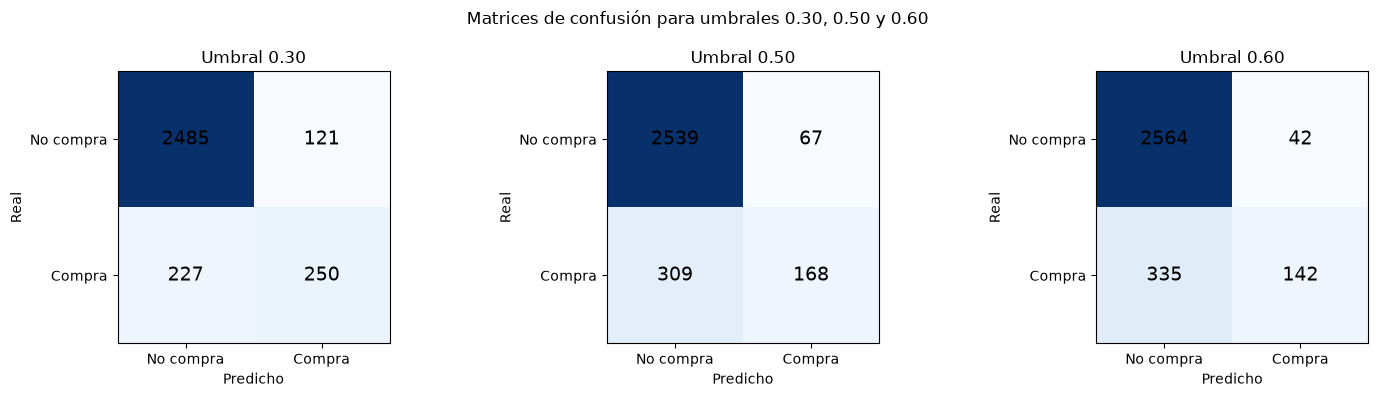

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, umbral in zip(axes, [0.30, 0.50, 0.60]):
    m = confusion_matrix(y_test, predicciones[umbral])
    ax.imshow(m, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, m[i, j], ha="center", va="center", fontsize=14)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["No compra", "Compra"])
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["No compra", "Compra"])
    ax.set_xlabel("Predicho")
    ax.set_ylabel("Real")
    ax.set_title(f"Umbral {umbral:.2f}")
plt.suptitle("Matrices de confusión para umbrales 0.30, 0.50 y 0.60")
plt.tight_layout()
plt.savefig("../reports/figures/11_matrices_umbrales.png", dpi=150, bbox_inches="tight")
plt.show()

In [20]:
print("=== Resumen para el informe (sección 11) ===")
for umbral in [0.30, 0.50, 0.60]:
    y_pred_u = predicciones[umbral]
    p, r, f, _ = precision_recall_fscore_support(y_test, y_pred_u, pos_label=1)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_u).ravel()
    acc = accuracy_score(y_test, y_pred_u)
    print(f"Umbral {umbral:.2f}: Accuracy={acc:.4f}, Precision(clase 1)={p[1]:.4f}, "
          f"Recall(clase 1)={r[1]:.4f}, F1(clase 1)={f[1]:.4f} | TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print(f"Predicciones que cambian -> 0.30 vs 0.50: {(y_pred_030 != y_pred_050).sum()}; "
      f"0.60 vs 0.50: {(y_pred_060 != y_pred_050).sum()}")

=== Resumen para el informe (sección 11) ===
Umbral 0.30: Accuracy=0.8871, Precision(clase 1)=0.6739, Recall(clase 1)=0.5241, F1(clase 1)=0.5896 | TN=2485, FP=121, FN=227, TP=250
Umbral 0.50: Accuracy=0.8780, Precision(clase 1)=0.7149, Recall(clase 1)=0.3522, F1(clase 1)=0.4719 | TN=2539, FP=67, FN=309, TP=168
Umbral 0.60: Accuracy=0.8777, Precision(clase 1)=0.7717, Recall(clase 1)=0.2977, F1(clase 1)=0.4297 | TN=2564, FP=42, FN=335, TP=142
Predicciones que cambian -> 0.30 vs 0.50: 136; 0.60 vs 0.50: 51


## 12. Experimento con class_weight='balanced'

Repetimos el entrenamiento equilibrando el peso de las clases
(`class_weight='balanced'`) para mitigar el desbalance y comparamos el resultado
contra el modelo base.

In [21]:
modelo_balanced = Pipeline(
    steps=[
        ("preprocesador", preprocesador),
        ("clasificador", LogisticRegression(max_iter=1000, class_weight="balanced")),
    ]
)

modelo_balanced.fit(X_train, y_train)
y_pred_bal = modelo_balanced.predict(X_test)

accuracy_bal = accuracy_score(y_test, y_pred_bal)
matriz_bal = confusion_matrix(y_test, y_pred_bal)
tn_b, fp_b, fn_b, tp_b = matriz_bal.ravel()
p_b, r_b, f_b, _ = precision_recall_fscore_support(y_test, y_pred_bal, pos_label=1)

print("Accuracy (balanced):", accuracy_bal)
print("\nMatriz de confusión (balanced):")
print(matriz_bal)
print("\n=== classification_report (balanced) ===")
print(classification_report(y_test, y_pred_bal))

Accuracy (balanced): 0.8553357119688615

Matriz de confusión (balanced):
[[2287  319]
 [ 127  350]]

=== classification_report (balanced) ===
              precision    recall  f1-score   support

           0       0.95      0.88      0.91      2606
           1       0.52      0.73      0.61       477

    accuracy                           0.86      3083
   macro avg       0.74      0.81      0.76      3083
weighted avg       0.88      0.86      0.86      3083



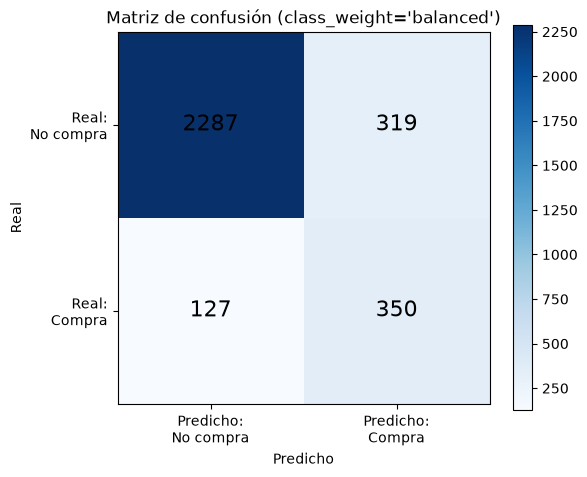

In [22]:
plt.figure(figsize=(6, 5))
plt.imshow(matriz_bal, cmap="Blues")
plt.colorbar()
for i in range(2):
    for j in range(2):
        plt.text(j, i, matriz_bal[i, j], ha="center", va="center", fontsize=16)
plt.xticks([0, 1], ["Predicho:\nNo compra", "Predicho:\nCompra"])
plt.yticks([0, 1], ["Real:\nNo compra", "Real:\nCompra"])
plt.xlabel("Predicho")
plt.ylabel("Real")
plt.title("Matriz de confusión (class_weight='balanced')")
plt.savefig("../reports/figures/12_matriz_confusion_balanced.png", dpi=150, bbox_inches="tight")
plt.show()

In [23]:
comparacion_modelos = pd.DataFrame({
    "Métrica": ["Accuracy", "Precision (clase 1)", "Recall (clase 1)", "F1 (clase 1)"],
    "Base": [accuracy, p_base[1], r_base[1], f_base[1]],
    "Balanced": [accuracy_bal, p_b[1], r_b[1], f_b[1]],
})

print("Comparación base vs. balanced:")
display(comparacion_modelos)

Comparación base vs. balanced:


,Métrica,Base,Balanced
0,Accuracy,0.878041,0.855336
1,Precision (clase 1),0.714894,0.523169
2,Recall (clase 1),0.352201,0.733753
3,F1 (clase 1),0.471910,0.610820


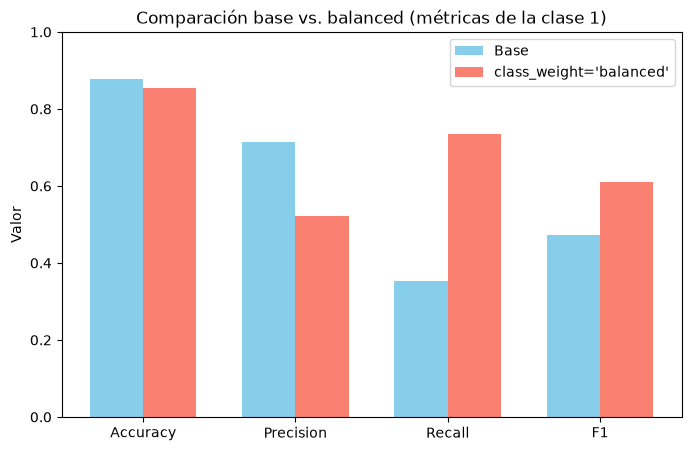

In [24]:
metricas_nombres = ["Accuracy", "Precision", "Recall", "F1"]
valores_base = [accuracy, p_base[1], r_base[1], f_base[1]]
valores_bal = [accuracy_bal, p_b[1], r_b[1], f_b[1]]

x = np.arange(len(metricas_nombres))
ancho = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x - ancho / 2, valores_base, ancho, label="Base", color="skyblue")
plt.bar(x + ancho / 2, valores_bal, ancho, label="class_weight='balanced'", color="salmon")
plt.xticks(x, metricas_nombres)
plt.ylim(0, 1)
plt.ylabel("Valor")
plt.title("Comparación base vs. balanced (métricas de la clase 1)")
plt.legend()
plt.savefig("../reports/figures/12_comparacion_base_vs_balanced.png", dpi=150, bbox_inches="tight")
plt.show()

In [25]:
print("=== Resumen para el informe (sección 12) ===")
print(f"Base      -> Accuracy={accuracy:.4f}, Precision(clase 1)={p_base[1]:.4f}, "
      f"Recall(clase 1)={r_base[1]:.4f}, F1(clase 1)={f_base[1]:.4f} | TN={TN}, FP={FP}, FN={FN}, TP={TP}")
print(f"Balanced  -> Accuracy={accuracy_bal:.4f}, Precision(clase 1)={p_b[1]:.4f}, "
      f"Recall(clase 1)={r_b[1]:.4f}, F1(clase 1)={f_b[1]:.4f} | TN={tn_b}, FP={fp_b}, FN={fn_b}, TP={tp_b}")

# Guardar métricas de todos los escenarios en un CSV
filas = []
for nombre, y_pred_esc in [
    ("base_0.50", y_pred),
    ("base_0.30", y_pred_030),
    ("base_0.60", y_pred_060),
    ("balanced_0.50", y_pred_bal),
    ("trivial", y_trivial),
]:
    acc = accuracy_score(y_test, y_pred_esc)
    p, r, f, _ = precision_recall_fscore_support(y_test, y_pred_esc, pos_label=1)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_esc).ravel()
    filas.append({
        "escenario": nombre,
        "accuracy": acc,
        "precision_1": p[1],
        "recall_1": r[1],
        "f1_1": f[1],
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    })

metricas_df = pd.DataFrame(filas)
metricas_df.to_csv("../reports/metricas.csv", index=False)
print("\nMétricas guardadas en ../reports/metricas.csv:")
display(metricas_df)

=== Resumen para el informe (sección 12) ===
Base      -> Accuracy=0.8780, Precision(clase 1)=0.7149, Recall(clase 1)=0.3522, F1(clase 1)=0.4719 | TN=2539, FP=67, FN=309, TP=168
Balanced  -> Accuracy=0.8553, Precision(clase 1)=0.5232, Recall(clase 1)=0.7338, F1(clase 1)=0.6108 | TN=2287, FP=319, FN=127, TP=350

Métricas guardadas en ../reports/metricas.csv:


/home/dev/.local/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


,escenario,accuracy,precision_1,recall_1,f1_1,TN,FP,FN,TP
0,base_0.50,0.878041,0.714894,0.352201,0.471910,2539,67,309,168
1,base_0.30,0.887123,0.673854,0.524109,0.589623,2485,121,227,250
2,base_0.60,0.877717,0.771739,0.297694,0.429652,2564,42,335,142
3,balanced_0.50,0.855336,0.523169,0.733753,0.610820,2287,319,127,350
4,trivial,0.845281,0.000000,0.000000,0.000000,2606,0,477,0


## Preguntas de interpretación

1. ¿Por qué este ejercicio es de clasificación y no de regresión?

   Respuesta: Porque la variable objetivo `Revenue` es una categoría binaria
   (compra / no compra), no una cantidad numérica continua. El modelo debe
   predecir una **clase** (0 o 1), no un valor numérico; por eso se usa
   regresión logística para clasificación.

2. ¿Qué significa que la variable compra tenga valores 0 y 1?

   Respuesta: Es una codificación binaria: 0 = "no compra" y 1 = "compra".
   La regresión logística usa esos valores para estimar la probabilidad de que
   una observación pertenezca a la clase positiva (compra).

3. ¿Qué hace fit() en el modelo?

   Respuesta: `fit()` **entrena** el modelo: estima los parámetros (los
   coeficientes de la regresión logística) a partir de los datos de
   entrenamiento. Al estar dentro del `Pipeline`, también ajusta el
   preprocesador (escalado y one-hot) únicamente con el conjunto de train.

4. ¿Qué diferencia hay entre predict() y predict_proba()?

   Respuesta: `predict()` devuelve la **clase predicha** (0 o 1) aplicando un
   umbral (0.50 por defecto) sobre la probabilidad. `predict_proba()` devuelve
   la **probabilidad** de pertenecer a cada clase, información más rica que
   permite cambiar el umbral de decisión (sección 11).

5. ¿Qué indica la matriz de confusión en este ejercicio?

   Respuesta: Resume los aciertos y errores por clase. Con el modelo base y
   umbral 0.50: TN=2539, FP=67, FN=309 y TP=168. Esto muestra que el modelo
   acierta casi siempre en "no compra", pero deja escapar muchas compras
   (recall de la clase 1 bajo: 0.352).

6. ¿Qué métrica considera más útil para interpretar el resultado y por qué?

   Respuesta: El **F1 (o el recall) de la clase "compra"**, no el accuracy.
   Como la clase positiva es minoritaria (~15%), el accuracy engaña: un modelo
   trivial que siempre dice "no compra" ya alcanza 0.845. El F1 equilibra
   precisión y recall sobre la clase minoritaria, que es la de interés.

7. ¿Qué podría pasar si el conjunto de datos fuera mucho más grande y estuviera desbalanceado?

   Respuesta: El accuracy sería aún menos informativo y el modelo tendería a
   predecir siempre la clase mayoritaria, ignorando la minoritaria. Sería
   necesario estratificar el split, usar `class_weight="balanced"` (o
   sobremuestreo) y evaluar con precision/recall/F1 en lugar de accuracy.